# Introduction to Molecular Mechanics and Dynamics 

---

### High-Level Questions
- What drives the binding of ligands to proteins?
- How does a protein fold into it's native state?
- How does molecular behavior at the atomic scale translate to bulk thermodynamic properties? <br>

![Lignad Binding](../assets/images/LigandBinding.png) 
**citation**<br>
Sohraby F, Nunes-Alves A
Advances in computational methods for ligand binding kinetics
Trends in Biochemical Sciences, 2022; 48, 437-449 

[Ligand Binding Molecular Dynamics](https://www.youtube.com/shorts/G48pFBgbqPM)


----

### Quantum Mechanics 
Quantum mechanics governs how particles evolve over time at the molecular and subatomic levels. In other words, classical physics breaks down at these lengths scales.

$i\hbar\frac{\partial \Psi}{\partial t} = \hat{H}\Psi$ : Time dependent Schrodinger equation<br>
$\hat{H}\Psi = E\Psi$ : Time independent Schrodinger equation <br>

$\hat{H} = \hat{K} + \hat{V}$ <br>
The Hamiltonian operator represents the total energy of a system, which is the sum of the kinetic energy operator plus the potential energy operator<br>

Even with our best and most accurate quantum chemical approximations, simulating 10s-100s atoms is impractical for most research labs. <br>

<span style="color: red;">**Can we come up with simple classical approximations to model the behavior of molecules?**.</span><br>

---

# Molecular Mechanics

**Classical Force Fields**:
- Come up with a simple functional form to describe the potential energy along coordinate
- Define what common chemical environments may behave similarly.
  - Does the oxygen atom in a ketone behave the same as in an amide? <br>
  ![Lignad Binding](../assets/images/ketone_vs_amide.png)


- Fit simple functional forms to quantum mechanical and experimental data
  - each terms has a set of parameters that changes the "shape" of the function to an extent

**Modern approaches**: 
- Machine learning force fields 
- Using machine learning algorithms to define the chemical environment
- Using machine learning algorithms for training classical force fields 


---

## Valence Terms / Intramolecular Terms

<span style="color: red;">**Two Body Term:**</span><br>
How do we describe a chemical bond? 

In [46]:
import numpy as np
import nglview as nv
from ase import Atoms
from rdkit import Chem
from rdkit.Chem import AllChem 
from rdkit.Chem import rdMolTransforms


mol = Chem.MolFromSmiles('O')
mol = Chem.AddHs(mol)
AllChem.EmbedMolecule(mol)
base_conf = mol.GetConformer(0)

# Linear scan distances (Forward scan)
forward_scan = np.linspace(0.80, 1.20, 15)  # Stretch from 0.8Å to 1.2Å
single_sweep = np.concatenate([forward_scan, forward_scan[::-1]]) 
full_scan = np.tile(single_sweep, 10)

ase_frames = []
for i, length in enumerate(full_scan):
    new_conf = Chem.Conformer(base_conf)
    rdMolTransforms.SetBondLength(new_conf, 0, 1, length)
    
    symbols = [atom.GetSymbol() for atom in mol.GetAtoms()]
    positions = new_conf.GetPositions()
    ase_frames.append(Atoms(symbols=symbols, positions=positions))

trajectory = nv.ASETrajectory(ase_frames)
view = nv.NGLWidget(trajectory)
view.layout.height = '200px'   

view.center()
view

NGLWidget(layout=Layout(height='200px'), max_frame=299)

In [47]:
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import plotly.graph_objects as go

def compute_morse_potential(distances, alpha=1.8, r_eq= 2.0, well_depth=20.0):
    """
    computer a morse potential given an array of distances

    :param distances: bond distances
    :param alpha: 
    :param r_eq: equilibrium distance in Angstroms
    :param well_depth: dissociation energy in kcal/mol

    :return energies: kcal/mol
    """
    return well_depth*(1 - np.exp(-alpha*(distances - r_eq)))**2

distances = np.linspace(1.6, 5.0, 100)
v_curve = compute_morse_potential(distances)

req = 2.0
delta = 0.2
n_points = 40 
min_r = req - delta
max_r = req + delta
displacement = req / 2.0
forward_r = np.linspace(min_r, max_r, n_points)
single_oscillation_r = np.concatenate([forward_r, forward_r[::-1]])
samples_distances = np.tile(single_oscillation_r, 4)

forward_a = np.linspace(displacement-(delta/2), displacement+(delta/2), n_points)[::-1] # Starts flipped
single_oscillation_a = np.concatenate([forward_a, forward_a[::-1]])
atom_a_x = np.tile(single_oscillation_a, 4)

forward_b = np.linspace((displacement+req)-(delta/2), (displacement+req)+(delta/2), n_points)
single_oscillation_b = np.concatenate([forward_b, forward_b[::-1]])
atom_b_x = np.tile(single_oscillation_b, 4)

# Compute energy based on the updated structural distances loop
sampled_energies = compute_morse_potential(samples_distances)


fig = go.Figure(
    data=[
        go.Scatter(x=distances, y=v_curve, mode='lines', line=dict(color='gray', dash='dash'), showlegend=False),
        go.Scatter(x=samples_distances, y=sampled_energies, mode='markers', name='Energy State'),
        go.Scatter(x=atom_a_x, y=[0.1], mode='markers', marker=dict(size=18, color='blue'), xaxis='x2', name='Atom 1'),
        go.Scatter(x=atom_b_x, y=[0.1], mode='markers', marker=dict(size=18, color='blue'), xaxis='x2', name='Atom 2')
    ],
    frames=[go.Frame(data=[
        go.Scatter(),
        go.Scatter(x=[samples_distances[i]], y=[sampled_energies[i]]),
        go.Scatter(x=[atom_a_x[i]]),
        go.Scatter(x=[atom_b_x[i]])
    ]) for i, _ in enumerate(samples_distances)]
)

fig.update_layout(
    xaxis=dict(title="Bond Length (r)", range=[1.6, 5.0]),
    xaxis2=dict(title="Position: x", range=[0, 17.0], side='top', overlaying='x', showgrid=False),
    yaxis=dict(title="Energy (kcal/mol)", range=[-0.8, 20.0]),
    updatemenus=[dict(type="buttons", buttons=[dict(label="Play", method="animate", args=[None, dict(frame=dict(duration=25, redraw=False))])])]
)

fig.show()


<span style="color: red;">**What if we focus on the minium?**</span><br>

In [48]:


fig = go.Figure(
    data=[
        go.Scatter(x=distances, y=v_curve, mode='lines', line=dict(color='gray', dash='dash'), showlegend=False),
        go.Scatter(x=samples_distances, y=sampled_energies, mode='markers', name='Energy State'),
        go.Scatter(x=atom_a_x, y=[0.1], mode='markers', marker=dict(size=18, color='blue'), xaxis='x2', name='Atom 1'),
        go.Scatter(x=atom_b_x, y=[0.1], mode='markers', marker=dict(size=18, color='blue'), xaxis='x2', name='Atom 2')
    ],
    frames=[go.Frame(data=[
        go.Scatter(),
        go.Scatter(x=[samples_distances[i]], y=[sampled_energies[i]]),
        go.Scatter(x=[atom_a_x[i]]),
        go.Scatter(x=[atom_b_x[i]])
    ]) for i, _ in enumerate(samples_distances)]
)

fig.update_layout(
    xaxis=dict(title="Bond Length (r)", range=[1.8, 2.2]),
    xaxis2=dict(title="Position: x", range=[0.9, 3.1], side='top', overlaying='x', showgrid=False),
    yaxis=dict(title="Energy (kcal/mol)", range=[0.0, 4.0]),
    updatemenus=[dict(type="buttons", buttons=[dict(label="Play", method="animate", args=[None, dict(frame=dict(duration=25, redraw=False))])])]
)

fig.show()



Perhaps a harmonic potential?

$E = \frac{1}{2}k(r - r_{eq})^2$





In [49]:
def compute_bond_stretch(distances, k=80.0, r_eq=2.0):
    return k * (distances - r_eq)**2

bond_stretch_ene = compute_bond_stretch(distances, k=20.0)

fig = go.Figure(
    data=[
        go.Scatter(x=distances, y=v_curve, mode='lines', line=dict(color='gray', dash='dash'), name='Reference'),
        go.Scatter(x=distances, y=bond_stretch_ene, mode='lines', line=dict(color='red', dash='dash'), name='Harmonic Potential'),
        go.Scatter(x=samples_distances, y=sampled_energies, mode='markers', name='Energy State'),
        go.Scatter(x=atom_a_x, y=[0.1], mode='markers', marker=dict(size=18, color='blue'), xaxis='x2', name='Atom 1'),
        go.Scatter(x=atom_b_x, y=[0.1], mode='markers', marker=dict(size=18, color='blue'), xaxis='x2', name='Atom 2')
    ],
    frames=[go.Frame(data=[
        go.Scatter(),
        go.Scatter(),
        go.Scatter(x=[samples_distances[i]], y=[sampled_energies[i]]),
        go.Scatter(x=[atom_a_x[i]]),
        go.Scatter(x=[atom_b_x[i]])
    ]) for i, _ in enumerate(samples_distances)]
)

fig.update_layout(
    xaxis=dict(title="Bond Length (r)", range=[1.8, 2.2]),
    xaxis2=dict(title="Position: x", range=[0.9, 3.1], side='top', overlaying='x', showgrid=False),
    yaxis=dict(title="Energy (kcal/mol)", range=[0.0, 4.0]),
    updatemenus=[dict(type="buttons", buttons=[dict(label="Play", method="animate", args=[None, dict(frame=dict(duration=25, redraw=False))])])]
)

fig.show()

In [50]:
bond_stretch_ene = compute_bond_stretch(distances, k=100)

fig = go.Figure(
    data=[
        go.Scatter(x=distances, y=v_curve, mode='lines', line=dict(color='gray', dash='dash'), name='Reference'),
        go.Scatter(x=distances, y=bond_stretch_ene, mode='lines', line=dict(color='red', dash='dash'), name='Harmonic Potential'),
        go.Scatter(x=samples_distances, y=sampled_energies, mode='markers', name='Energy State'),
        go.Scatter(x=atom_a_x, y=[0.1], mode='markers', marker=dict(size=18, color='blue'), xaxis='x2', name='Atom 1'),
        go.Scatter(x=atom_b_x, y=[0.1], mode='markers', marker=dict(size=18, color='blue'), xaxis='x2', name='Atom 2')
    ],
    frames=[go.Frame(data=[
        go.Scatter(),
        go.Scatter(),
        go.Scatter(x=[samples_distances[i]], y=[sampled_energies[i]]),
        go.Scatter(x=[atom_a_x[i]]),
        go.Scatter(x=[atom_b_x[i]])
    ]) for i, _ in enumerate(samples_distances)]
)

fig.update_layout(
    xaxis=dict(title="Bond Length (r)", range=[1.6, 5.0]),
    xaxis2=dict(title="Position: x", range=[0, 17.0], side='top', overlaying='x', showgrid=False),
    yaxis=dict(title="Energy (kcal/mol)", range=[-0.8, 20.0]),
    updatemenus=[dict(type="buttons", buttons=[dict(label="Play", method="animate", args=[None, dict(frame=dict(duration=25, redraw=False))])])]
)

fig.show()



<span style="color: red;">**Where does the harmonic approximation fail?**</span><br>



<span style="color: Green;">**Three Body Term:**</span><br>
How do we describe the potential w.r.t. a bond angle? 

In [51]:
import numpy as np
import nglview as nv
from ase import Atoms
from rdkit import Chem
from rdkit.Chem import AllChem 
from rdkit.Chem import rdMolTransforms


mol = Chem.MolFromSmiles('O')
mol = Chem.AddHs(mol)
AllChem.EmbedMolecule(mol)
base_conf = mol.GetConformer(0)

# Linear scan angle (Forward scan)
forward_scan = np.linspace(80.0, 120.0, 15)  # bend from 80.0 deg - 120 deg
single_sweep = np.concatenate([forward_scan, forward_scan[::-1]]) 
full_scan = np.tile(single_sweep, 2)

ase_frames = []
for i, angle in enumerate(full_scan):
    new_conf = Chem.Conformer(base_conf)
    rdMolTransforms.SetAngleDeg(new_conf, 1, 0, 2, angle)
    
    symbols = [atom.GetSymbol() for atom in mol.GetAtoms()]
    positions = new_conf.GetPositions()
    ase_frames.append(Atoms(symbols=symbols, positions=positions))

trajectory = nv.ASETrajectory(ase_frames)
view = nv.NGLWidget(trajectory)
view.layout.height = '200px'   

view.center()
view

NGLWidget(layout=Layout(height='200px'), max_frame=59)


Again a harmonic potential what is typically used<br>

$E = \frac{1}{2}k(\theta - \theta_{eq})^2$ <br>

**Where does the harmonic approximation fail for bond bending?**

If the atoms positions are provided in cartesian coordinates how would compute $\theta$ <br>

<span style="color: Green;">**Four Body Term:**</span><br>
How do we describe the potential w.r.t. a dihedral? 

In [57]:
import numpy as np
import nglview as nv
from ase import Atoms
from rdkit import Chem
from rdkit.Chem import AllChem 
from rdkit.Chem import rdMolTransforms

peptide_smiles = "C[C@@H](C(=O)O)N"
mol = Chem.MolFromSmiles(peptide_smiles)
mol = Chem.AddHs(mol)
AllChem.EmbedMolecule(mol)
base_conf = mol.GetConformer(0)

# Linear scan torsion (Forward scan)
forward_scan = np.linspace(60.0, 160.0, 30) 
single_sweep = np.concatenate([forward_scan, forward_scan[::-1]]) 
full_scan = np.tile(single_sweep, 2)

ase_frames = []
for i, angle in enumerate(full_scan):
    new_conf = Chem.Conformer(base_conf)
    rdMolTransforms.SetDihedralDeg(new_conf, 2, 1, 5, 8, angle)
    
    symbols = [atom.GetSymbol() for atom in mol.GetAtoms()]
    positions = new_conf.GetPositions()
    ase_frames.append(Atoms(symbols=symbols, positions=positions))

trajectory = nv.ASETrajectory(ase_frames)
view = nv.NGLWidget(trajectory)
view.layout.height = '200px'   

view.center()
view


NGLWidget(layout=Layout(height='200px'), max_frame=119)

## Dihedral 

Uses a Fourier Series 

$E_{dihedral} = \frac{V_1}{2}(1 + cos (\phi)) + \frac{V_2}{2}(1 - cos (2\phi)) + \frac{V_3}{2}(1 + cos (3\phi)) +\frac{V_4}{2}(1 - cos (4\phi))$


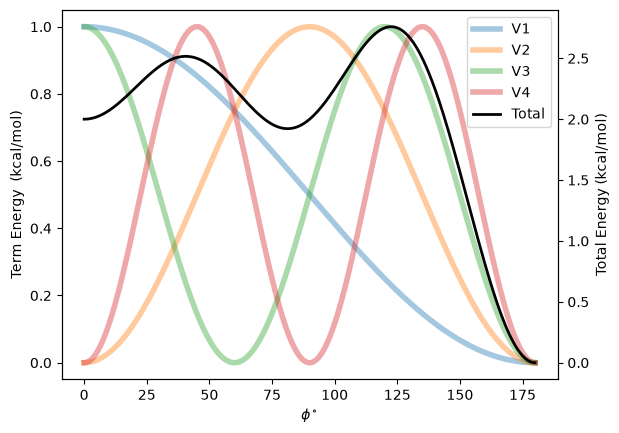

In [113]:
import matplotlib.pyplot as plt

def compute_dihedral_energy(angles, v1=2.0, v2=3.0, v3=0.0, v4=0.0):
    v1_term = (v1/2.) * (1 + np.cos(angles))
    v2_term = (v2/2.) * (1 - np.cos(2.0*angles))
    v3_term = (v3/2.) * (1 + np.cos(3.0*angles))
    v4_term = (v4/2.) * (1 - np.cos(4.0*angles))
    return v1_term + v2_term + v3_term + v4_term

angles = np.linspace(0, 180, 360)
radians = np.deg2rad(angles)
pot1 = compute_dihedral_energy(radians, v1=1.0, v2=0.0, v3=0.0, v4=0.0)
v1 = pot1 - np.min(pot1)
pot2 = compute_dihedral_energy(radians, v1=0.0, v2=1.0, v3=0.0, v4=0.0)
v2 = pot2 - np.min(pot2)
pot3 = compute_dihedral_energy(radians, v1=0.0, v2=0.0, v3=1.0, v4=0.0)
v3 = pot3 - np.min(pot3)
pot4 = compute_dihedral_energy(radians, v1=0.0, v2=0.0, v3=0.0, v4=1.0)
v4 = pot4 - np.min(pot4)

total = (v1+v2+v3+v4)

fig, ax1 = plt.subplots()

ax1.set_xlabel('$\phi^{\circ}$')
ax1.set_ylabel('Term Energy  (kcal/mol)')
a1l1 = ax1.plot(angles, v1, linewidth=4.0, alpha=0.4, label='V1')
a1l2 = ax1.plot(angles, v2, linewidth=4.0, alpha=0.4, label='V2')
a1l3 = ax1.plot(angles, v3, linewidth=4.0, alpha=0.4, label='V3')
a1l4 = ax1.plot(angles, v4, linewidth=4.0, alpha=0.4, label='V4')

ax2 = ax1.twinx()
ax2.set_ylabel('Total Energy (kcal/mol)')
a2l = ax2.plot(angles, total, linewidth=2.0, alpha=0.99, color='black', label='Total')
lns = a1l1 + a1l2 + a1l3 + a1l4 + a2l
labs = [l.get_label() for l in lns]
ax1.legend(lns, labs)


<span style="color: red;">**Why truncate at the $V_4$ term?**</span><br>

---


## Nonbonded Terms:
- Electrostatics
- Van der Waals forces

---


#### **Electrostatics**:

**Quantum Chemistry**<br>
Electron density and electrostatic potential 

In [121]:
import nglview as nv

# Initialize the NGL Viewer widget
view = nv.NGLWidget()

# 1. Load the density cube file as your base component (holds structure + shape)
density_comp = view.add_component('benzene_density.cube')

# 2. Load the ESP cube file as your potential grid reference
esp_comp = view.add_component('benzene_esp.cube')

# 3. Clear default representations from the ESP data grid component
# esp_comp.clear()

# 4. Add the molecular surface mapped with electrostatic colors
density_comp.add_surface(
    color_scheme='volume',      
    color_volume=esp_comp,      
    colorScale='rwb',           
    colorDomain=[-0.03, 0.03],
    isolevelType="value",   
    isolevel=0.02,              
    opacity=0.75                
)

# 5. Display the interactive widget block
view

NGLWidget()

In [73]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

# --- PHYSICAL PREFERENCES ---
# Distances are implicitly in Angstroms (Å)
# Energy output is in kcal/mol
COULOMB_K = 332.0637  # kcal * Å / (mol * e^2)
Q_TEST = -1.0         # Test charge value

# 1. Define EXACTLY ONE fixed set of point charges (in units of elementary charge 'e')
fixed_charges = [
    {'q':  3.0, 'x':  0.7, 'y':  0.7},
    {'q': -2.0, 'x': -0.7, 'y':  0.7},
    {'q':  2.5, 'x': -0.7, 'y': -0.7},
    {'q': -2.0, 'x':  0.7, 'y': -0.7}
]

# 2. Set up static viewport grid for the Energy Map (in Angstroms)
grid_size = 120
limit = 3.0  # Å
x_grid = np.linspace(-limit, limit, grid_size)
y_grid = np.linspace(-limit, limit, grid_size)
X, Y = np.meshgrid(x_grid, y_grid)

# 3. DYNAMICALLY COMPUTE MULTIPOLE MOMENTS DIRECTLY FROM THE CHARGES
Q_mono = sum(c['q'] for c in fixed_charges)
p_x = sum(c['q'] * c['x'] for c in fixed_charges)
p_y = sum(c['q'] * c['y'] for c in fixed_charges)

Q_xx, Q_yy, Q_xy = 0.0, 0.0, 0.0
for c in fixed_charges:
    r_prime_sq = c['x']**2 + c['y']**2
    Q_xx += c['q'] * (3 * c['x']**2 - r_prime_sq)
    Q_yy += c['q'] * (3 * c['y']**2 - r_prime_sq)
    Q_xy += c['q'] * (3 * c['x'] * c['y'])

# 4. Define the 1D evaluation path (Along the diagonal x=y line, theta = pi/4)
r_curve = np.linspace(15.0, 1.0, 100)  # From 15 Å down to 1 Å
theta = np.pi / 4.0
nx, ny = np.cos(theta), np.sin(theta)

# Compute precise analytical 1D Potential Terms (Volts/equivalent scale)
v_mono = Q_mono / r_curve
v_dip  = v_mono + (p_x * nx + p_y * ny) / (r_curve**2)
v_quad = v_dip  + (0.5 * (Q_xx * nx**2 + 2 * Q_xy * nx * ny + Q_yy * ny**2)) / (r_curve**3)

# Convert Potential curves to Interaction Energy (kcal/mol) -> E = k_e * q_test * V
e_mono = COULOMB_K * Q_TEST * v_mono
e_dip  = COULOMB_K * Q_TEST * v_dip
e_quad = COULOMB_K * Q_TEST * v_quad

%matplotlib inline

# 5. Interactive Draw Loop
def update_expansion(r_current):
    # Scale factor mimics zooming in toward the origin
    scale = 1.0 - (r_current - 1.0) / (15.0 - 1.0)
    scale = np.maximum(scale, 0.04)
    
    # Calculate exact Potential (V)
    V = np.zeros_like(X)
    for c in fixed_charges:
        cx_scaled = c['x'] * scale
        cy_scaled = c['y'] * scale
        distance = np.sqrt((X - cx_scaled)**2 + (Y - cy_scaled)**2)
        V += c['q'] / np.maximum(distance, 0.25)
        
    # Convert entire 2D matrix layout to Interaction Energy (kcal/mol)
    E_exact = COULOMB_K * Q_TEST * V
    E_clipped = np.clip(E_exact, -600.0, 600.0) # Clipped for visualization bounds
    
    if r_current > 8.0:
        desc = "Far-Field"
    elif r_current > 3.0:
        desc = "Mid-Field"
    else:
        desc = "Near-Field"
        
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
    fig.suptitle(f"Multipole Expansion (r = {r_current:.1f} Å | {desc})", fontsize=14, y=0.98)
    
    # Left Subplot: Exact Interaction Energy Map (kcal/mol)
    im = ax1.imshow(E_clipped, extent=[-limit, limit, -limit, limit], origin='lower', cmap='RdBu', vmin=-600.0, vmax=600.0)
    ax1.set_title(f"Exact Interaction Energy (q_test = {Q_TEST})")
    ax1.set_xlabel("X Position (Å)")
    ax1.set_ylabel("Y Position (Å)")
    cbar = fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)
    cbar.set_label("Interaction Energy (kcal/mol)")
    
    # Right Subplot: Dynamic Energy Falloff Curves
    ax2.plot(r_curve, e_mono, 'b-', label="Monopole (1/r)", alpha=0.7)
    ax2.plot(r_curve, e_dip, 'g-', label="Mono + Dipole (1/r²)", alpha=0.7)
    ax2.plot(r_curve, e_quad, 'r-', label="Mono + Dipole + Quad (1/r³)", linewidth=2.5)
    
    # Moving distance bar tracker
    ax2.axvline(x=r_current, color='black', linestyle='--', linewidth=3, label="Observer Distance (r)")
    
    ax2.set_xlim(15.5, 0.5) 
    ax2.set_ylim(min(e_quad) - 50, max(e_quad) + 50)
    ax2.set_title(f"Energy vs. Distance (Along θ = {np.degrees(theta):.0f}°)")
    ax2.set_xlabel("Distance from Center r (Å)")
    ax2.set_ylabel("Interaction Energy (kcal/mol)")
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc="upper left" if Q_TEST < 0 else "upper right")
    
    plt.tight_layout()
    plt.show()

interact(update_expansion, r_current=widgets.FloatSlider(
    value=15.0, min=1.0, max=15.0, step=0.2,
    description='Distance r (Å):', continuous_update=True, layout=widgets.Layout(width='600px')
));


interactive(children=(FloatSlider(value=15.0, description='Distance r (Å):', layout=Layout(width='600px'), max…

In [114]:
from pyscf import gto, scf
from pyscf.tools import cubegen

mol = gto.M(
    atom='''
    C   0.000000   1.397000   0.000000
    C   1.209838   0.698500   0.000000
    C   1.209838  -0.698500   0.000000
    C   0.000000  -1.397000   0.000000
    C  -1.209838  -0.698500   0.000000
    C  -1.209838   0.698500   0.000000
    H   0.000000   2.481000   0.000000
    H   2.148609   1.240500   0.000000
    H   2.148609  -1.240500   0.000000
    H   0.000000  -2.481000   0.000000
    H  -2.148609  -1.240500   0.000000
    H  -2.148609   1.240500   0.000000
    ''',
    basis='6-31g*' # Standard basis set for organic systems
)

# 2. Run Restrained Hartree-Fock (RHF) to converge the wavefunction
mf = scf.RHF(mol).run()

# 3. Extract the 1-electron Reduced Density Matrix (RDM1)
dm = mf.make_rdm1()

# 4. Generate Gaussian Cube files
# 'benzene_density.cube' defines the shape of the molecule's electron cloud
cubegen.density(mol, 'benzene_density.cube', dm)

# 'benzene_esp.cube' tracks the electrostatic potential value at each grid point
cubegen.mep(mol, 'benzene_esp.cube', dm)

converged SCF energy = -230.701463439209


array([[[0.00198883, 0.00204186, 0.00209478, ..., 0.00209478,
         0.00204186, 0.00198883],
        [0.00205389, 0.00211087, 0.00216779, ..., 0.00216779,
         0.00211087, 0.00205389],
        [0.00212126, 0.00218253, 0.0022438 , ..., 0.0022438 ,
         0.00218253, 0.00212126],
        ...,
        [0.00212126, 0.00218253, 0.0022438 , ..., 0.0022438 ,
         0.00218253, 0.00212126],
        [0.00205389, 0.00211087, 0.00216779, ..., 0.00216779,
         0.00211087, 0.00205389],
        [0.00198883, 0.00204186, 0.00209478, ..., 0.00209478,
         0.00204186, 0.00198883]],

       [[0.00202086, 0.00207641, 0.00213188, ..., 0.00213188,
         0.00207641, 0.00202086],
        [0.00208646, 0.00214621, 0.00220594, ..., 0.00220594,
         0.00214621, 0.00208646],
        [0.00215437, 0.00221869, 0.00228305, ..., 0.00228305,
         0.00221869, 0.00215437],
        ...,
        [0.00215437, 0.00221869, 0.00228305, ..., 0.00228305,
         0.00221869, 0.00215437],
        [0.0

# Introduction to Statistical Mechanics 

---